In [2]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Set random seeds to ensure reproducible results
tf.keras.utils.set_random_seed(42)

# Define dataset directories
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET_DIR = BASE_DIR / "dataset"
TRAIN_DIR = DATASET_DIR / "Training"
TEST_DIR = DATASET_DIR / "Testing"

# Global pipeline hyperparameters
IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)
BATCH_SIZE = 32

print("TensorFlow Version:", tf.__version__)
print("GPU Available     :", len(tf.config.list_physical_devices('GPU')) > 0)
print("Training Path     :", TRAIN_DIR)


TensorFlow Version: 2.21.0
GPU Available     : False
Training Path     : d:\Brain_Tumor\dataset\Training


In [3]:
# 1. Training Dataset (80% of dataset/Training)
raw_train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="categorical",
    shuffle=True
)

# 2. Validation Dataset (20% of dataset/Training)
raw_val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="categorical",
    shuffle=False
)

# 3. Print out detected class labels and verify alphabetical order
class_names = raw_train_ds.class_names
print("\nDetected Classes:", class_names)
print(f"Number of Classes: {len(class_names)}")


Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.

Detected Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of Classes: 4


In [4]:
# Extract a single batch from the training dataset
for images, labels in raw_train_ds.take(1):
    print("--- Batch Tensor Inspection ---")
    print(f"Image Batch Shape : {images.shape}")
    print(f"Labels Batch Shape: {labels.shape}")
    print(f"Image Data Type   : {images.dtype}")
    print(f"Labels Data Type  : {labels.dtype}")
    print(f"Pixel Min Value   : {images.numpy().min():.2f}")
    print(f"Pixel Max Value   : {images.numpy().max():.2f}")
    print("\nFirst Image's One-Hot Label Vector:")
    print(labels[0].numpy(), "--> Class:", class_names[np.argmax(labels[0])])


--- Batch Tensor Inspection ---
Image Batch Shape : (32, 224, 224, 3)
Labels Batch Shape: (32, 4)
Image Data Type   : <dtype: 'float32'>
Labels Data Type  : <dtype: 'float32'>
Pixel Min Value   : 0.00
Pixel Max Value   : 255.00

First Image's One-Hot Label Vector:
[0. 1. 0. 0.] --> Class: meningioma


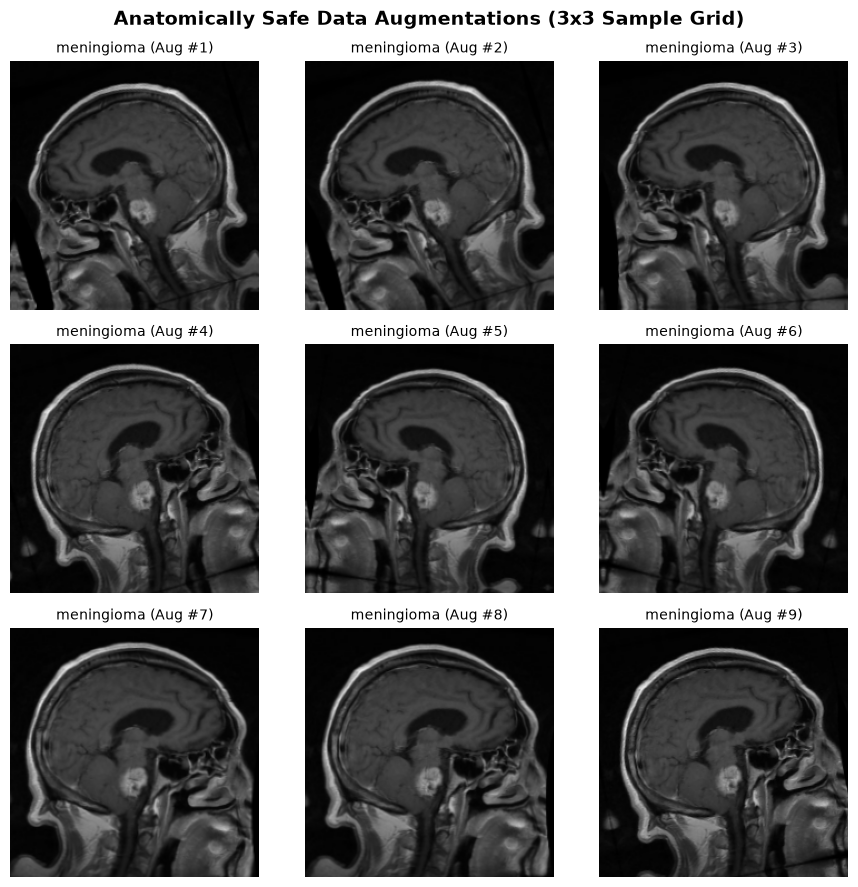

In [5]:
# 1. Define safe, clinically sound data augmentation layers
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05), # ~18 degrees max tilt
    tf.keras.layers.RandomZoom(0.05),     # 5% max zoom
], name="data_augmentation")

# 2. Visualize the effect of augmentation on one MRI image
sample_image = images[0] # Take the first image from our inspected batch
sample_class = class_names[np.argmax(labels[0])]

plt.figure(figsize=(9, 9))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    # Pass training=True to activate the random transformations
    augmented_image = data_augmentation(tf.expand_dims(sample_image, 0), training=True)
    plt.imshow(augmented_image[0].numpy().astype("uint8"))
    plt.title(f"{sample_class} (Aug #{i+1})", fontsize=10)
    plt.axis("off")

plt.suptitle("Anatomically Safe Data Augmentations (3x3 Sample Grid)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


In [6]:
AUTOTUNE = tf.data.AUTOTUNE

# 1. Load the untouched Testing dataset (for Phase 6 final evaluation)
raw_test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="categorical",
    shuffle=False
)

# 2. Apply caching and prefetching to all splits
# For training: cache -> shuffle with buffer -> prefetch
train_ds = raw_train_ds.cache().shuffle(buffer_size=1000).prefetch(buffer_size=AUTOTUNE)

# For validation & testing: cache -> prefetch (no shuffle)
val_ds = raw_val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = raw_test_ds.cache().prefetch(buffer_size=AUTOTUNE)

print("\n--- Pipeline Optimization Complete ---")
print(f"Training Batches   : {len(train_ds)} (Total: {len(train_ds) * BATCH_SIZE} capacity)")
print(f"Validation Batches : {len(val_ds)} (Total: {len(val_ds) * BATCH_SIZE} capacity)")
print(f"Testing Batches    : {len(test_ds)} (Total: {len(test_ds) * BATCH_SIZE} capacity)")


Found 1600 files belonging to 4 classes.



--- Pipeline Optimization Complete ---
Training Batches   : 140 (Total: 4480 capacity)
Validation Batches : 35 (Total: 1120 capacity)
Testing Batches    : 50 (Total: 1600 capacity)


In [7]:
from tensorflow.keras import layers, models

# 1. Load pretrained MobileNetV2 base (without top classification layer)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    include_top=False,
    weights="imagenet"
)

# 2. Freeze the base feature extractor
base_model.trainable = False

# 3. Assemble the model pipeline using Keras Functional API
inputs = tf.keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3), name="input_image")

# Step A: Data Augmentation (active only during training)
x = data_augmentation(inputs)

# Step B: Normalize pixels from [0, 255] to [-1, 1] as expected by MobileNetV2
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

# Step C: Extract features using frozen base (training=False keeps BatchNorm stats frozen)
x = base_model(x, training=False)

# Step D: Spatial pooling to prevent parameter explosion
x = layers.GlobalAveragePooling2D(name="global_avg_pooling")(x)
x = layers.BatchNormalization(name="batch_norm_1")(x)
x = layers.Dropout(0.3, name="dropout_1")(x)

# Step E: Dense classification head
x = layers.Dense(128, activation="relu", name="dense_128")(x)
x = layers.BatchNormalization(name="batch_norm_2")(x)
x = layers.Dropout(0.2, name="dropout_2")(x)

# Step F: Final 4-class output
outputs = layers.Dense(4, activation="softmax", name="output_predictions")(x)

# 4. Construct the complete Model object
model = models.Model(inputs=inputs, outputs=outputs, name="Brain_Tumor_MobileNetV2")

# 5. Print architectural summary
model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "Brain_Tumor_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pooling              │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1                    │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_2                    │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_predictions (Dense)      │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,428,100 (9.26 MB)

 Trainable params: 167,300 (653.52 KB)

 Non-trainable params: 2,260,800 (8.62 MB)

In [8]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

# 1. Compile the model
INITIAL_LEARNING_RATE = 1e-3

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=INITIAL_LEARNING_RATE),
    loss=tf.keras.losses.CategoricalCrossentropy(),
    metrics=["accuracy"]
)

# 2. Define checkpoint save path inside our dedicated 'models/' directory
MODEL_SAVE_PATH = BASE_DIR / "models" / "brain_tumor_mobilenetv2_best.keras"

# 3. Setup production callbacks
callbacks = [
    # Guard 1: Always preserve the single best model weights on disk
    ModelCheckpoint(
        filepath=str(MODEL_SAVE_PATH),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),
    # Guard 2: Halt training when learning saturates (prevents overfitting)
    EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    # Guard 3: Fine-tune step size when loss plateaus
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("Model compiled successfully!")
print(f"Checkpoint destination configured: {MODEL_SAVE_PATH}")


Model compiled successfully!
Checkpoint destination configured: d:\Brain_Tumor\models\brain_tumor_mobilenetv2_best.keras


In [ ]:
EPOCHS = 20

print(f"Beginning model training for up to {EPOCHS} epochs...")
print("=" * 60)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

print("=" * 60)
print("Training session finished!")


In [9]:
import tensorflow as tf
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# 1. Load the best saved model checkpoint from disk
MODEL_PATH = BASE_DIR / "models" / "brain_tumor_mobilenetv2_best.keras"
print(f"Loading best saved model from: {MODEL_PATH}")
model = tf.keras.models.load_model(MODEL_PATH)
print("Model loaded successfully!\n")

# 2. Evaluate on the untouched test split
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"\nFinal Test Loss     : {test_loss:.4f}")
print(f"Final Test Accuracy : {test_accuracy * 100:.2f}%\n")

# 3. Predict on test dataset
y_pred_probs = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)

# Extract ground-truth labels
y_true = np.concatenate([y.numpy() for x, y in test_ds], axis=0)
y_true = np.argmax(y_true, axis=1)

# 4. Detailed Classification Report
print("\n" + "=" * 60)
print("             DETAILED CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))


Loading best saved model from: d:\Brain_Tumor\models\brain_tumor_mobilenetv2_best.keras
Model loaded successfully!

50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 230ms/step - accuracy: 0.8219 - loss: 0.5601

Final Test Loss     : 0.5601
Final Test Accuracy : 82.19%

50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 221ms/step

             DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma     0.9075    0.6625    0.7659       400
  meningioma     0.7864    0.6350    0.7026       400
     notumor     0.8655    0.9975    0.9268       400
   pituitary     0.7576    0.9925    0.8593       400

    accuracy                         0.8219      1600
   macro avg     0.8293    0.8219    0.8137      1600
weighted avg     0.8293    0.8219    0.8137      1600



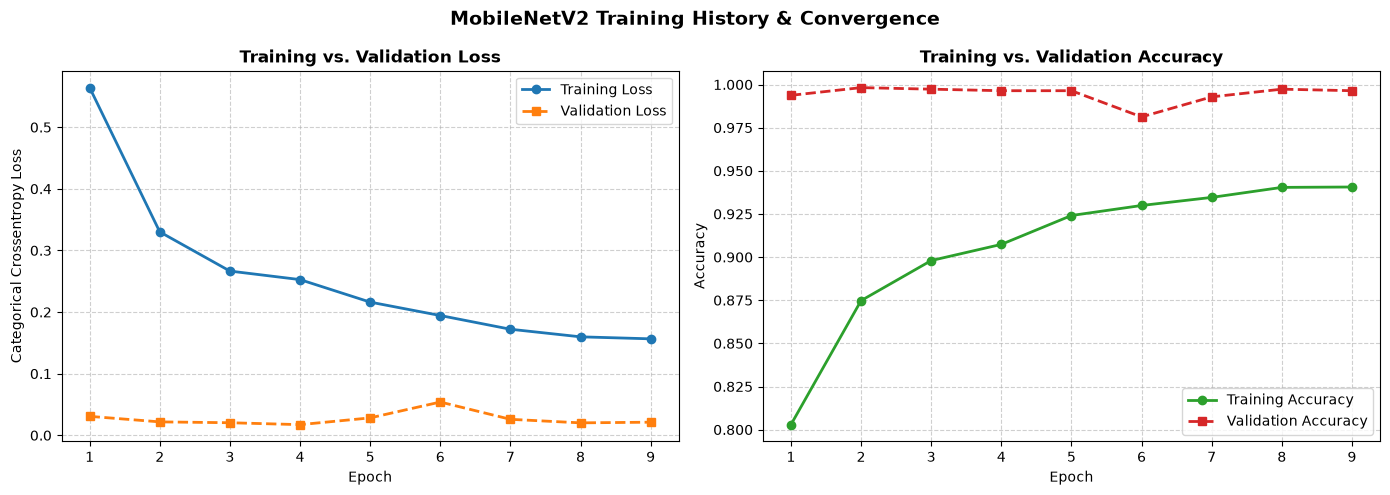

In [10]:
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

# Plot 1: Loss curves
plt.subplot(1, 2, 1)
plt.plot(epochs_range, loss, "o-", label="Training Loss", color="#1f77b4", linewidth=2)
plt.plot(epochs_range, val_loss, "s--", label="Validation Loss", color="#ff7f0e", linewidth=2)
plt.title("Training vs. Validation Loss", fontsize=12, fontweight="bold")
plt.xlabel("Epoch")
plt.ylabel("Categorical Crossentropy Loss")
plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.6)

# Plot 2: Accuracy curves
plt.subplot(1, 2, 2)
plt.plot(epochs_range, acc, "o-", label="Training Accuracy", color="#2ca02c", linewidth=2)
plt.plot(epochs_range, val_acc, "s--", label="Validation Accuracy", color="#d62728", linewidth=2)
plt.title("Training vs. Validation Accuracy", fontsize=12, fontweight="bold")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)

plt.suptitle("MobileNetV2 Training History & Convergence", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


In [7]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# 1. Evaluate on the untouched test split
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"\nFinal Test Loss     : {test_loss:.4f}")
print(f"Final Test Accuracy : {test_accuracy * 100:.2f}%\n")

# 2. Extract true labels and model predictions
# Note: test_ds has shuffle=False, preserving sample order
y_pred_probs = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)

# Extract ground-truth labels from the dataset batches
y_true = np.concatenate([y.numpy() for x, y in test_ds], axis=0)
y_true = np.argmax(y_true, axis=1)

# 3. Detailed Per-Class Classification Report
print("\n" + "=" * 60)
print("             DETAILED CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))


NameError: name 'model' is not defined

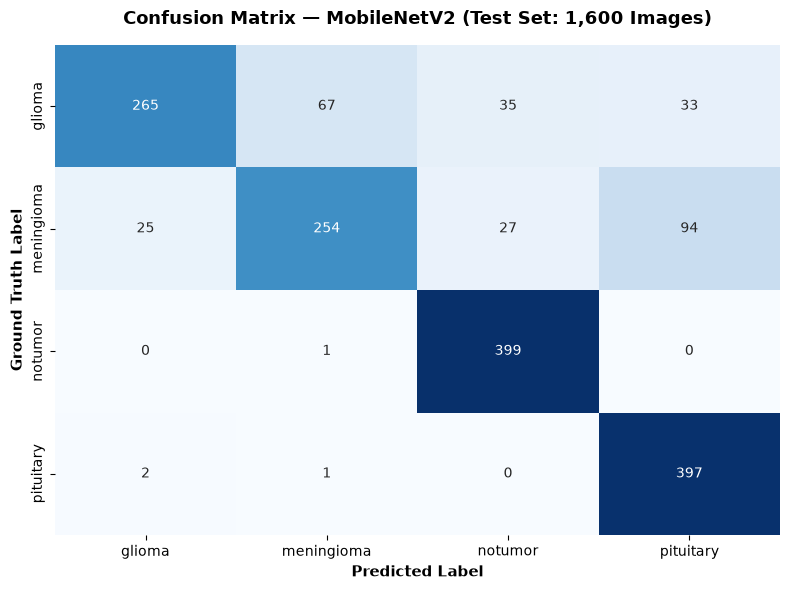

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, 
    annot=True, 
    fmt="d", 
    cmap="Blues", 
    xticklabels=class_names, 
    yticklabels=class_names,
    cbar=False
)
plt.title("Confusion Matrix — MobileNetV2 (Test Set: 1,600 Images)", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Predicted Label", fontsize=11, fontweight="bold")
plt.ylabel("Ground Truth Label", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()


In [11]:
# 1. Load 100% of the Training Directory (5,600 images total)
full_raw_train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="categorical",
    shuffle=True,
    seed=42
)

# 2. Optimize pipeline for training
full_train_ds = full_raw_train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

print(f"\nTotal Full Training Batches: {len(full_train_ds)} (Total Images: {len(full_train_ds) * BATCH_SIZE})")


Found 5600 files belonging to 4 classes.

Total Full Training Batches: 175 (Total Images: 5600)


In [12]:
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau

# 1. Instantiate a fresh MobileNetV2 base (frozen)
fresh_base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    include_top=False,
    weights="imagenet"
)
fresh_base_model.trainable = False

# 2. Build the computational graph
inputs = tf.keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3), name="input_image")
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = fresh_base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name="global_avg_pooling")(x)
x = layers.BatchNormalization(name="batch_norm_1")(x)
x = layers.Dropout(0.3, name="dropout_1")(x)
x = layers.Dense(128, activation="relu", name="dense_128")(x)
x = layers.BatchNormalization(name="batch_norm_2")(x)
x = layers.Dropout(0.2, name="dropout_2")(x)
outputs = layers.Dense(4, activation="softmax", name="output_predictions")(x)

# 3. Create the fresh model
full_model = models.Model(inputs=inputs, outputs=outputs, name="Brain_Tumor_MobileNetV2_Full")

# 4. Compile with 1e-3 learning rate for the fresh head
full_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.CategoricalCrossentropy(),
    metrics=["accuracy"]
)

# 5. Dedicated checkpoint path
FULL_MODEL_PATH = BASE_DIR / "models" / "brain_tumor_mobilenetv2_full_scratch.keras"

callbacks_full = [
    ModelCheckpoint(
        filepath=str(FULL_MODEL_PATH),
        monitor="loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="loss",
        mode="min",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

# 6. Train on all 5,600 images
EPOCHS_FULL = 8

print(f"Training fresh model on all 5,600 images for {EPOCHS_FULL} epochs...")
print("=" * 60)

history_full = full_model.fit(
    full_train_ds,
    epochs=EPOCHS_FULL,
    callbacks=callbacks_full,
    verbose=1
)

print("=" * 60)
print(f"Training finished! Best weights saved to:\n{FULL_MODEL_PATH}")


Training fresh model on all 5,600 images for 8 epochs...
Epoch 1/8


d:\Brain_Tumor\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step - accuracy: 0.8166 - loss: 0.5161
Epoch 1: loss improved from None to 0.51609, saving model to d:\Brain_Tumor\models\brain_tumor_mobilenetv2_full_scratch.keras

Epoch 1: finished saving model to d:\Brain_Tumor\models\brain_tumor_mobilenetv2_full_scratch.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 50s 247ms/step - accuracy: 0.8166 - loss: 0.5161 - learning_rate: 0.0010
Epoch 2/8
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step - accuracy: 0.8857 - loss: 0.3147
Epoch 2: loss improved from 0.51609 to 0.31475, saving model to d:\Brain_Tumor\models\brain_tumor_mobilenetv2_full_scratch.keras

Epoch 2: finished saving model to d:\Brain_Tumor\models\brain_tumor_mobilenetv2_full_scratch.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 40s 230ms/step - accuracy: 0.8857 - loss: 0.3147 - learning_rate: 0.0010
Epoch 3/8
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step - accuracy: 0.9027 - loss: 0.2627
Epoch 3: loss improved from 0.31475 to 0.26266, saving model to d:\Brain_Tumor\models\brai

50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 223ms/step - accuracy: 0.8612 - loss: 0.4716

Model 1 (80% data) Test Accuracy : 82.19%  (Loss: 0.5601)
Model 2 (100% data) Test Accuracy: 86.12% (Loss: 0.4716)

50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 207ms/step

       FULL DATASET MODEL — CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma     0.9281    0.6775    0.7832       400
  meningioma     0.7949    0.7850    0.7899       400
     notumor     0.9167    0.9900    0.9519       400
   pituitary     0.8254    0.9925    0.9012       400

    accuracy                         0.8612      1600
   macro avg     0.8663    0.8612    0.8566      1600
weighted avg     0.8663    0.8612    0.8566      1600



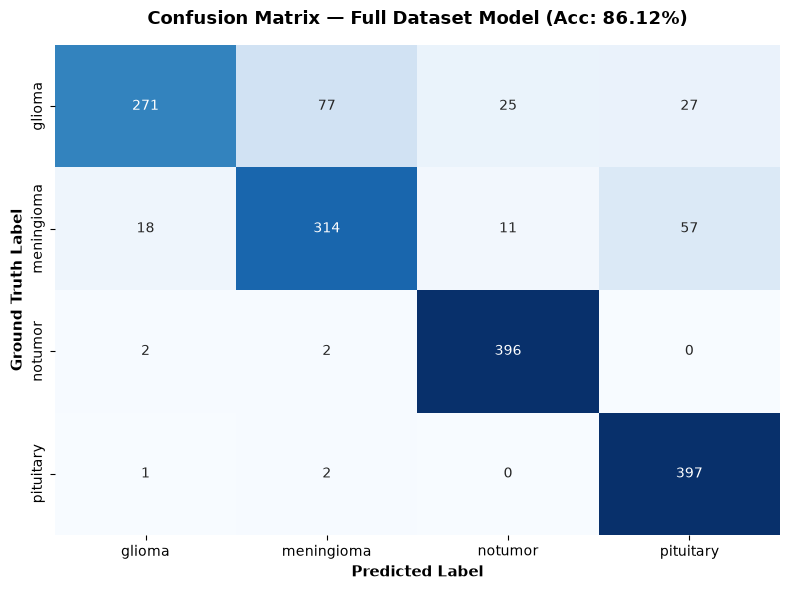

In [13]:
# 1. Load the best checkpoint from our full training run
best_full_model = tf.keras.models.load_model(FULL_MODEL_PATH)

# 2. Evaluate on the untouched test split
full_test_loss, full_test_accuracy = best_full_model.evaluate(test_ds, verbose=1)
print(f"\n============================================================")
print(f"Model 1 (80% data) Test Accuracy : 82.19%  (Loss: 0.5601)")
print(f"Model 2 (100% data) Test Accuracy: {full_test_accuracy * 100:.2f}% (Loss: {full_test_loss:.4f})")
print(f"============================================================\n")

# 3. Predict on test dataset
y_pred_probs_full = best_full_model.predict(test_ds, verbose=1)
y_pred_full = np.argmax(y_pred_probs_full, axis=1)

# 4. Detailed Classification Report
print("\n" + "=" * 60)
print("       FULL DATASET MODEL — CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_true, y_pred_full, target_names=class_names, digits=4))

# 5. Plot the Confusion Matrix
cm_full = confusion_matrix(y_true, y_pred_full)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_full, 
    annot=True, 
    fmt="d", 
    cmap="Blues", 
    xticklabels=class_names, 
    yticklabels=class_names,
    cbar=False
)
plt.title(f"Confusion Matrix — Full Dataset Model (Acc: {full_test_accuracy*100:.2f}%)", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Predicted Label", fontsize=11, fontweight="bold")
plt.ylabel("Ground Truth Label", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()


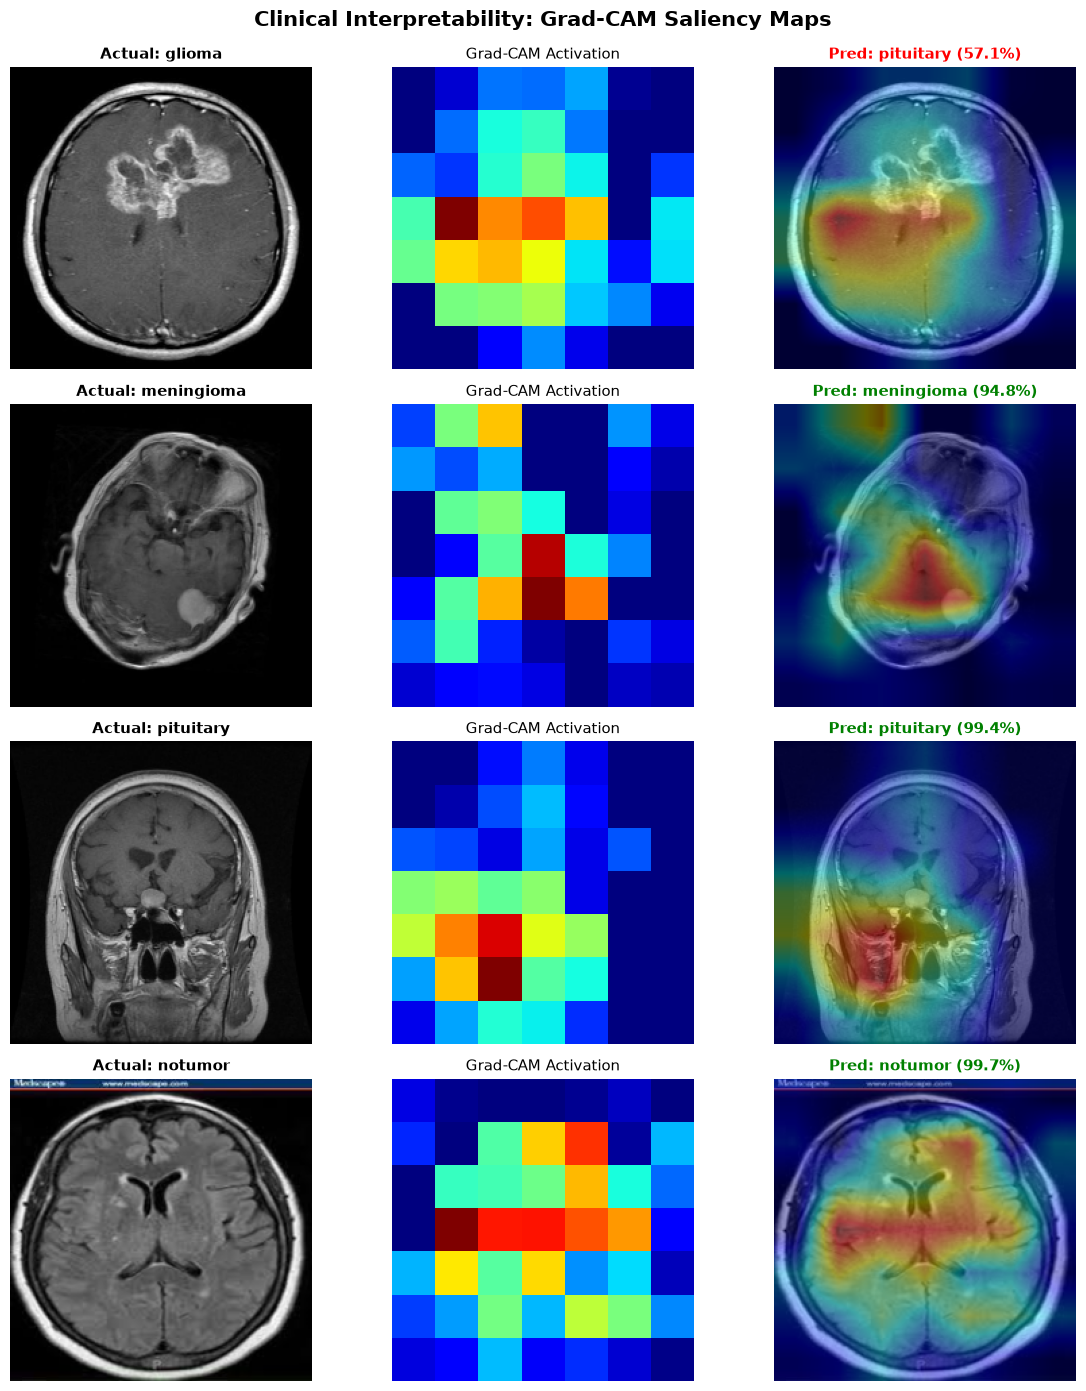

In [14]:
import cv2
import glob

# 1. Core Grad-CAM Generation Function
def make_gradcam_heatmap(img_array, model, pred_index=None):
    # Locate the base model inside our functional architecture
    base_model = [l for l in model.layers if 'mobilenet' in l.name.lower()][0]
    
    # Preprocess image as MobileNetV2 expects (scaling to [-1, 1])
    prep_img = tf.keras.applications.mobilenet_v2.preprocess_input(img_array)
    
    with tf.GradientTape() as tape:
        # Step A: Extract spatial feature maps from the base model
        conv_features = base_model(prep_img, training=False)
        tape.watch(conv_features)
        
        # Step B: Pass features through the classification head
        x = conv_features
        for layer in model.layers[3:]:
            x = layer(x, training=False)
        preds = x
        
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_score = preds[:, pred_index]

    # Step C: Gradients of the class score with respect to the feature maps
    grads = tape.gradient(class_score, conv_features)
    
    # Step D: Global average pooling of gradients (importance weight of each filter)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    
    # Step E: Weighted sum of feature maps
    heatmap = conv_features[0] @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    
    # Step F: Apply ReLU to keep only features that positively contributed to the class
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-10)
    return heatmap.numpy(), preds[0].numpy(), pred_index.numpy()

# 2. Function to create a side-by-side diagnostic visualization
def overlay_gradcam(original_img_rgb, heatmap, alpha=0.4):
    # Resize heatmap to match image dimensions
    heatmap_resized = cv2.resize(heatmap, (original_img_rgb.shape[1], original_img_rgb.shape[0]))
    heatmap_uint8 = np.uint8(255 * heatmap_resized)
    
    # Convert heatmap to JET colormap (Red = high attention, Blue = low)
    jet_colormap = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    jet_colormap = cv2.cvtColor(jet_colormap, cv2.COLOR_BGR2RGB)
    
    # Superimpose heatmap onto original grayscale/RGB image
    superimposed = np.uint8(original_img_rgb * (1 - alpha) + jet_colormap * alpha)
    return superimposed

# 3. Test Grad-CAM across 1 sample from each test class
fig, axes = plt.subplots(4, 3, figsize=(12, 14))
sample_classes = ["glioma", "meningioma", "pituitary", "notumor"]

for row_idx, cls_name in enumerate(sample_classes):
    # Grab the first image from each test class directory
    img_files = sorted(glob.glob(f"../dataset/Testing/{cls_name}/*.jpg")) or sorted(glob.glob(f"dataset/Testing/{cls_name}/*.jpg"))
    sample_path = img_files[0]
    
    # Load and format image
    raw_img = cv2.imread(sample_path)
    raw_img = cv2.resize(raw_img, (IMG_HEIGHT, IMG_WIDTH))
    raw_img_rgb = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)
    img_tensor = np.expand_dims(raw_img_rgb.astype("float32"), axis=0)
    
    # Generate Grad-CAM
    heatmap, probs, pred_idx = make_gradcam_heatmap(img_tensor, best_full_model)
    superimposed_img = overlay_gradcam(raw_img_rgb, heatmap)
    
    pred_label = class_names[pred_idx]
    confidence = probs[pred_idx] * 100
    
    # Column 1: Original MRI
    axes[row_idx, 0].imshow(raw_img_rgb)
    axes[row_idx, 0].set_title(f"Actual: {cls_name}", fontsize=11, fontweight="bold")
    axes[row_idx, 0].axis("off")
    
    # Column 2: Raw Heatmap
    axes[row_idx, 1].imshow(heatmap, cmap="jet")
    axes[row_idx, 1].set_title("Grad-CAM Activation", fontsize=11)
    axes[row_idx, 1].axis("off")
    
    # Column 3: Superimposed Diagnostic Overlay
    axes[row_idx, 2].imshow(superimposed_img)
    axes[row_idx, 2].set_title(f"Pred: {pred_label} ({confidence:.1f}%)", 
                               fontsize=11, 
                               color="green" if pred_label == cls_name else "red", 
                               fontweight="bold")
    axes[row_idx, 2].axis("off")

plt.suptitle("Clinical Interpretability: Grad-CAM Saliency Maps", fontsize=15, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()
